<a href="https://colab.research.google.com/github/swopnil8848/E-governance-dummy-project-_/blob/main/self_Linear_Regression_for_Predicting_Price_of_second_hand_Cars_by_Neuralearn_ai_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as ts # deep learning modeling
import pandas as pd # reading and processing data
import seaborn as sns # visulizations
from tensorflow.keras.layers import Normalization,Dense,InputLayer
from tensorflow.keras.losses import MeanSquaredError, MeanAbsoluteError, Huber
from tensorflow.keras.metrics import RootMeanSquaredError
from tensorflow.keras.optimizers import Adam, AdamW
import matplotlib.pyplot as plt

In [ ]:
## **Data Preparation**

In [ ]:
filepath = "/content/train.csv"

In [ ]:
data = pd.read_csv(filepath, sep=",")

In [ ]:
data.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [ ]:
data.shape

(4009, 12)

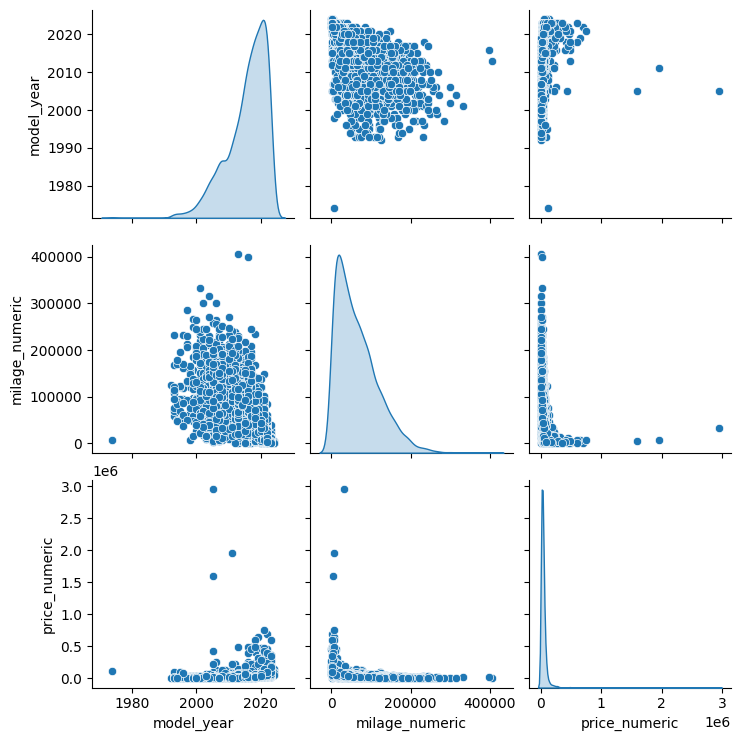

In [ ]:
data['milage_numeric'] = data['milage'].str.replace(' mi.', '', regex=False).str.replace(',', '', regex=False).astype(float)
data['price_numeric'] = data['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
sns.pairplot(data[['model_year', 'milage_numeric', 'price_numeric']], diag_kind='kde')

In [ ]:
shuffled_data = ts.random.shuffle(data)

ValueError: Failed to convert a NumPy array to a Tensor (Unsupported object type int).

In [ ]:
shuffled_data[:5]

In [ ]:
x = shuffled_data[:,3:-1]
y = ts.expand_dims(shuffled_data[:,-1],-1)

In [ ]:
print(x.shape,y.shape)

In [ ]:
TRAIN_RATIO = 0.8
VAL_RATIO = 0.1
TEST_RATIO = 0.1
DATASET_SIZE = len(x)
print(DATASET_SIZE)

In [ ]:
X_train = x[:int(DATASET_SIZE*TRAIN_RATIO)]
y_train = y[:int(DATASET_SIZE*TRAIN_RATIO)]
print(X_train.shape,y_train.shape)

In [ ]:
X_val = x[int(DATASET_SIZE*TRAIN_RATIO):int(DATASET_SIZE*(TRAIN_RATIO+VAL_RATIO))]
y_val = y[int(DATASET_SIZE*TRAIN_RATIO):int(DATASET_SIZE*(TRAIN_RATIO+VAL_RATIO))]
print(X_val.shape,y_val.shape)

In [ ]:
X_test = x[int(DATASET_SIZE*(TRAIN_RATIO+VAL_RATIO)):]
y_test = y[int(DATASET_SIZE*(TRAIN_RATIO+VAL_RATIO)):]
print(X_test.shape,y_test.shape)

In [ ]:
BUFFER_SIZE = 16
BATCH_SIZE = 64

In [ ]:
train_dataset = ts.data.Dataset.from_tensor_slices((X_train,y_train))
train_dataset = train_dataset.shuffle(buffer_size=BUFFER_SIZE).batch(BATCH_SIZE).prefetch(ts.data.AUTOTUNE)

In [ ]:
for i,j in train_dataset:
  print(i,j)
  break

In [ ]:
val_dataset = ts.data.Dataset.from_tensor_slices((X_val,y_val))
val_dataset = val_dataset.shuffle(buffer_size=BUFFER_SIZE).batch(BATCH_SIZE).prefetch(ts.data.AUTOTUNE)

In [ ]:
test_dataset = ts.data.Dataset.from_tensor_slices((X_test,y_test))
test_dataset = test_dataset.shuffle(buffer_size=BUFFER_SIZE).batch(BATCH_SIZE).prefetch(ts.data.AUTOTUNE)

In [ ]:
a = ts.constant([[3,4,5,6,7],[4,5,6,7,8]])
normalizer = Normalization(axis=1)
normalizer.adapt(a)
print(normalizer(a))

In [ ]:

normalizer = Normalization()
normalizer.adapt(X_train)
X_normalized = normalizer(X_train)[:5]

In [ ]:
print(X_normalized)

In [ ]:
model = ts.keras.Sequential([
    normalizer,
    Dense(1)
],name = "first-sequential-api")
model.summary()

Sequential API
Functional APi

In [ ]:
model = ts.keras.Sequential()
model.add(normalizer)
model.add(Dense(1))
model.summary()

In [ ]:
model = ts.keras.Sequential([
    InputLayer(input_shape=(8,)),
    normalizer,
    Dense(128, activation='relu'),
    Dense(128,activation='relu'),
    Dense(128,activation='relu'),
    Dense(1)
],name="first-sequential-api")
model.summary()

In [ ]:
model.compile(optimizer=Adam(learning_rate=1e-3),loss=ts.keras.losses.Huber())

In [ ]:
y.shape

In [ ]:
x.shape

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.1),
    loss=MeanAbsoluteError(),
    metrics=[RootMeanSquaredError()]
)

In [ ]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=100,
    verbose=1
)

In [ ]:
history.history["loss"]

In [ ]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Model Loss")
plt.ylabel("Loss")
plt.xlabel("Epoch")
plt.legend(["train","val_loss"])
plt.show()

In [ ]:
plt.plot(history.history["root_mean_squared_error"])
plt.plot(history.history["val_root_mean_squared_error"])
plt.title("Model perforamte (rmse)")
plt.ylabel("RMSE")
plt.xlabel("Epoch")
plt.legend(["train","val_root_mean_squared_error"])
plt.show()

In [ ]:
model.evaluate(val_dataset)

In [ ]:
model.evaluate(test_dataset)

In [ ]:
X_test[0]

In [ ]:
y_output = model.predict(ts.expand_dims(X_test[0], axis=0))

In [ ]:
print(y_output)

In [ ]:
y_pred = model(X_test)[:,0].numpy()
print(y_pred)

In [ ]:
y_true = y_test[:,0].numpy()
print(y_true)

In [ ]:
plt.figure(figsize=(40,20))
width = 0.1
plt.bar(ts.range(100).numpy(),y_pred,width,label='Model prediction')
plt.bar(ts.range(100).numpy() + width,y_true,width,label='Model prediction')
plt.xlabel("actual vs predicted price")
plt.ylabel(" car price")

plt.show()